# Aplicaciones Prácticas de BFGS, L-BFGS y Newton-CG

**Materia:** Métodos Numéricos II (`DAT-252`) — Carrera de Informática, UMSA  
**Objetivo:** Ver en acción cómo **BFGS**, **L-BFGS** y **Newton-CG** resuelven **3 problemas reales** (Machine Learning, Modelado de Datos y Visión por Computadora) con código corto, limpio y visual.

| # | Aplicación real | Variables ($n$) | Algoritmos usados | ¿Por qué brillan aquí? |
| :-: | :--- | :-: | :--- | :--- |
| **1** | **Riesgo crediticio** (Regresión Logística) | $n = 3$ | `BFGS` y `Newton-CG` | Son los motores reales que usa `scikit-learn` por debajo. |
| **2** | **Crecimiento de usuarios** (Curva Logística) | $n = 3$ | `BFGS` | Ajusta modelos no lineales usando solo el gradiente (sin segundas derivadas). |
| **3** | **Eliminación de ruido en imagen** (*Denoising*) | $n = 2{,}500$ | `Newton-CG` y `L-BFGS-B` | En alta dimensión no cabe la Hessiana ($6.25\times 10^6$ entradas); trabajan en memoria $O(n)$. |

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# Estilo visual limpio y semilla fija para reproducibilidad
plt.rcParams.update({
    "figure.dpi": 115,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 10,
})
rng = np.random.default_rng(42)
print("Entorno listo: NumPy, SciPy y Matplotlib cargados.")

Entorno listo: NumPy, SciPy y Matplotlib cargados.


---
## Ejemplo 1: Aprobación de Crédito con Regresión Logística (`BFGS` vs `Newton-CG`)

**Problema real:** Un banco quiere predecir la probabilidad de que un cliente **pague su crédito** ($y = 1$) o caiga en **mora** ($y = 0$) usando dos variables:
- $x_1$: Ingreso mensual (en miles de Bs)
- $x_2$: Porcentaje de endeudamiento (%)

Para entrenar el modelo buscamos los pesos $w = [b, w_1, w_2]$ que minimizan la **entropía cruzada regularizada (L2)**:
$$f(w) = -\frac{1}{N}\sum_{i=1}^{N}\Big[y_i \ln(\hat{p}_i) + (1 - y_i)\ln(1 - \hat{p}_i)\Big] + \frac{\lambda}{2}(w_1^2 + w_2^2), \qquad \hat{p}_i = \frac{1}{1 + e^{-X_i w}}$$

- **BFGS** solo necesita $f(w)$ y el gradiente $\nabla f(w)$.
- **Newton-CG** además usa el producto Hessiana–vector $\nabla^2 f(w)\,v = \frac{1}{N} X^T\big(\hat{p}(1-\hat{p})\odot (Xv)\big) + \lambda v_{\text{reg}}$, sin construir jamás la matriz Hessiana completa.

BFGS       | iter: 18 | pérdida: 0.379427 | exactitud: 85.6% | tiempo: 2.75 ms
Newton-CG  | iter:  6 | pérdida: 0.379427 | exactitud: 85.6% | tiempo: 1.32 ms


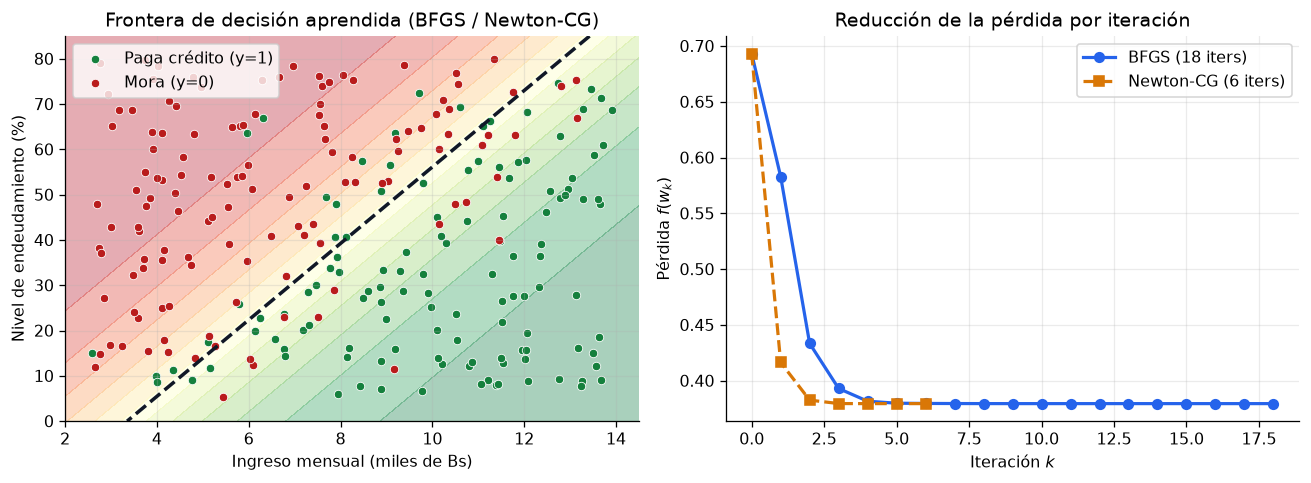

In [2]:
# 1) Generamos datos realistas de 250 solicitantes de crédito
N = 250
ingresos = rng.uniform(2.5, 14.0, N)      # miles de Bs / mes
deuda    = rng.uniform(5.0, 80.0, N)      # % de ingresos comprometidos

# Probabilidad real subyacente: más ingreso y menos deuda -> mayor probabilidad de pago
logits_reales = -0.5 + 0.75 * (ingresos - 7.5) - 0.11 * (deuda - 40.0)
prob_real = 1.0 / (1.0 + np.exp(-logits_reales))
y = (rng.uniform(0, 1, N) < prob_real).astype(float)

# Estandarizamos variables y agregamos columna de sesgo (intercepto)
X_raw = np.column_stack([ingresos, deuda])
mu, sigma = X_raw.mean(axis=0), X_raw.std(axis=0)
X = np.column_stack([np.ones(N), (X_raw - mu) / sigma])

lam = 1e-2  # regularización L2

def loss_logreg(w):
    z = X @ w
    # Forma numéricamente estable de la entropía cruzada binaria
    bce = np.mean(np.logaddexp(0.0, z) - y * z)
    return bce + 0.5 * lam * np.dot(w[1:], w[1:])

def grad_logreg(w):
    p = 1.0 / (1.0 + np.exp(-X @ w))
    reg = np.array([0.0, w[1], w[2]])
    return (X.T @ (p - y)) / N + lam * reg

def hessp_logreg(w, v):
    p = 1.0 / (1.0 + np.exp(-X @ w))
    d = p * (1.0 - p)
    reg_v = np.array([0.0, v[1], v[2]])
    return (X.T @ (d * (X @ v))) / N + lam * reg_v

# 2) Entrenamos con BFGS y con Newton-CG guardando el historial de pérdida
w0 = np.zeros(3)
hist = {}

for metodo in ["BFGS", "Newton-CG"]:
    curva = [loss_logreg(w0)]
    t0 = time.perf_counter()
    res = minimize(
        loss_logreg, w0,
        method=metodo,
        jac=grad_logreg,
        hessp=hessp_logreg if metodo == "Newton-CG" else None,
        callback=lambda wk: curva.append(loss_logreg(wk)),
        options={"gtol": 1e-8} if metodo == "BFGS" else {"xtol": 1e-8},
    )
    dt = (time.perf_counter() - t0) * 1000
    preds = (1.0 / (1.0 + np.exp(-X @ res.x)) >= 0.5).astype(float)
    acc = np.mean(preds == y) * 100
    hist[metodo] = (res, curva, dt, acc)
    print(f"{metodo:10s} | iter: {res.nit:2d} | pérdida: {res.fun:.6f} | exactitud: {acc:.1f}% | tiempo: {dt:.2f} ms")

w_opt = hist["BFGS"][0].x

# 3) Visualización: Frontera de decisión + Curva de convergencia
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.3))

# Panel izquierdo: Mapa de probabilidad y frontera de decisión
gx, gy = np.meshgrid(np.linspace(2.0, 14.5, 200), np.linspace(0.0, 85.0, 200))
G_std = (np.column_stack([gx.ravel(), gy.ravel()]) - mu) / sigma
P_grid = (1.0 / (1.0 + np.exp(-(np.column_stack([np.ones(gx.size), G_std]) @ w_opt)))).reshape(gx.shape)

ax1.contourf(gx, gy, P_grid, levels=15, cmap="RdYlGn", alpha=0.35)
ax1.contour(gx, gy, P_grid, levels=[0.5], colors="#111827", linewidths=2.2, linestyles="--")
ax1.scatter(ingresos[y == 1], deuda[y == 1], c="#15803d", s=28, edgecolors="white", lw=0.5, label="Paga crédito (y=1)")
ax1.scatter(ingresos[y == 0], deuda[y == 0], c="#b91c1c", s=28, edgecolors="white", lw=0.5, label="Mora (y=0)")
ax1.set_title("Frontera de decisión aprendida (BFGS / Newton-CG)")
ax1.set_xlabel("Ingreso mensual (miles de Bs)")
ax1.set_ylabel("Nivel de endeudamiento (%)")
ax1.legend(loc="upper left", frameon=True)

# Panel derecho: Velocidad de convergencia
ax2.plot(hist["BFGS"][1], "o-", color="#2563eb", lw=2, label=f"BFGS ({hist['BFGS'][0].nit} iters)")
ax2.plot(hist["Newton-CG"][1], "s--", color="#d97706", lw=2, label=f"Newton-CG ({hist['Newton-CG'][0].nit} iters)")
ax2.set_title("Reducción de la pérdida por iteración")
ax2.set_xlabel("Iteración $k$")
ax2.set_ylabel("Pérdida $f(w_k)$")
ax2.legend(frameon=True)

plt.tight_layout()
plt.show()

---
## Ejemplo 2: Predicción de Crecimiento de Usuarios — Curva Logística (`BFGS`)

**Problema real:** Una aplicación móvil registró sus usuarios activos durante sus primeros **20 meses** y necesita estimar su **techo de mercado** y proyectar los próximos 6 meses usando el modelo logístico de Verhulst:
$$\hat{y}(t; K, r, t_0) = \frac{K}{1 + e^{-r(t - t_0)}}$$
donde:
- $K$: capacidad máxima de mercado (miles de usuarios),
- $r$: velocidad de crecimiento mensual,
- $t_0$: mes del punto de inflexión (máximo crecimiento).

Minimizamos el **Error Cuadrático Medio (MSE)** $f(K, r, t_0) = \frac{1}{2N}\sum_{i=1}^N (\hat{y}(t_i) - y_i)^2$.  
Como el modelo es **no lineal**, calcular su Hessiana analítica a mano es tedioso; **BFGS** estima la curvatura automáticamente a partir de los gradientes y converge en pocas iteraciones.

BFGS convergió en 17 iteraciones (3.49 ms) | MSE final: 1.172
  Parámetros reales  : K = 50.00k | r = 0.420 | t0 = 10.50 meses
  Estimados por BFGS : K = 48.69k | r = 0.450 | t0 = 10.35 meses


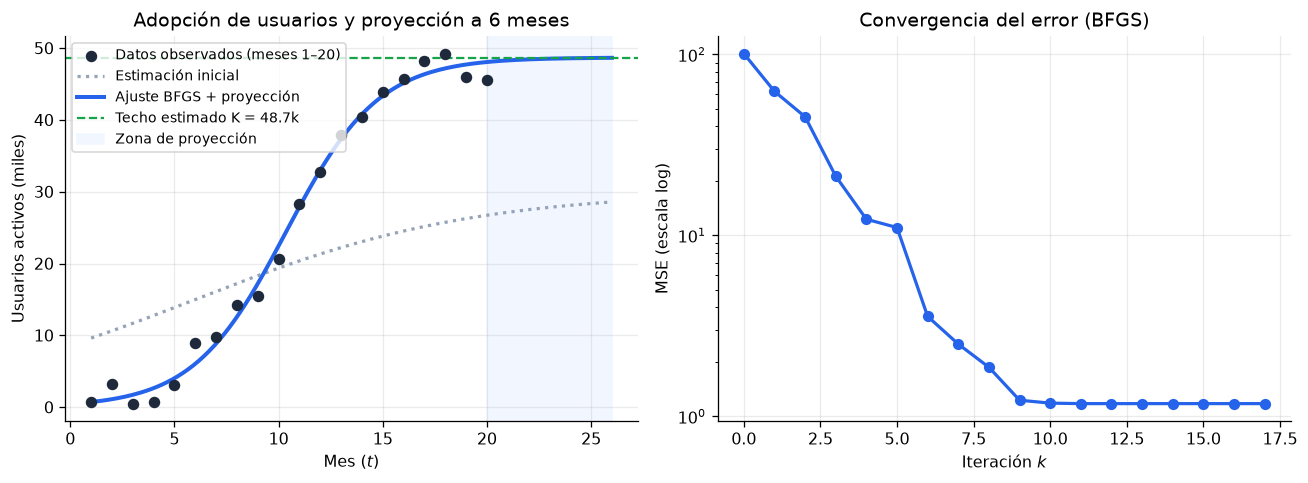

In [3]:
# 1) Datos observados durante 20 meses (con ruido realista de medición)
t_obs = np.arange(1, 21, dtype=float)
theta_real = np.array([50.0, 0.42, 10.5])  # [K=50k usuarios, r=0.42, t0=mes 10.5]

def curva_logistica(t, theta):
    K, r, t0 = theta
    return K / (1.0 + np.exp(-r * (t - t0)))

y_obs = curva_logistica(t_obs, theta_real) + rng.normal(0.0, 1.6, size=t_obs.size)
y_obs = np.clip(y_obs, 0.5, None)

# 2) Función objetivo (MSE) y su gradiente exacto (regla de la cadena)
def loss_curva(theta):
    err = curva_logistica(t_obs, theta) - y_obs
    return 0.5 * np.mean(err ** 2)

def grad_curva(theta):
    K, r, t0 = theta
    s = 1.0 / (1.0 + np.exp(-r * (t_obs - t0)))
    err = K * s - y_obs
    dK  = s
    dr  = K * s * (1.0 - s) * (t_obs - t0)
    dt0 = -K * s * (1.0 - s) * r
    return np.array([np.mean(err * dK), np.mean(err * dr), np.mean(err * dt0)])

# 3) Ajuste con BFGS desde una estimación inicial lejana
theta0 = np.array([30.0, 0.15, 6.0])
curva_mse = [loss_curva(theta0)]

t_ini = time.perf_counter()
res_curva = minimize(
    loss_curva, theta0,
    method="BFGS",
    jac=grad_curva,
    callback=lambda th: curva_mse.append(loss_curva(th)),
    options={"gtol": 1e-8},
)
dt_ms = (time.perf_counter() - t_ini) * 1000
K_est, r_est, t0_est = res_curva.x

print(f"BFGS convergió en {res_curva.nit} iteraciones ({dt_ms:.2f} ms) | MSE final: {res_curva.fun:.3f}")
print(f"  Parámetros reales  : K = {theta_real[0]:.2f}k | r = {theta_real[1]:.3f} | t0 = {theta_real[2]:.2f} meses")
print(f"  Estimados por BFGS : K = {K_est:.2f}k | r = {r_est:.3f} | t0 = {t0_est:.2f} meses")

# 4) Visualización: Ajuste + Proyección y Convergencia
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.3))

t_grid = np.linspace(1, 26, 200)
ax1.scatter(t_obs, y_obs, color="#1e293b", s=38, zorder=4, label="Datos observados (meses 1–20)")
ax1.plot(t_grid, curva_logistica(t_grid, theta0), ":", color="#94a3b8", lw=2, label="Estimación inicial")
ax1.plot(t_grid, curva_logistica(t_grid, res_curva.x), "-", color="#2563eb", lw=2.5, label="Ajuste BFGS + proyección")
ax1.axhline(K_est, color="#16a34a", ls="--", lw=1.4, label=f"Techo estimado K = {K_est:.1f}k")
ax1.axvspan(20, 26, color="#eff6ff", alpha=0.8, label="Zona de proyección")
ax1.set_title("Adopción de usuarios y proyección a 6 meses")
ax1.set_xlabel("Mes ($t$)")
ax1.set_ylabel("Usuarios activos (miles)")
ax1.legend(loc="upper left", fontsize=8.5, frameon=True)

ax2.semilogy(curva_mse, "o-", color="#2563eb", lw=2)
ax2.set_title("Convergencia del error (BFGS)")
ax2.set_xlabel("Iteración $k$")
ax2.set_ylabel("MSE (escala log)")

plt.tight_layout()
plt.show()

---
## Ejemplo 3: Limpieza de Ruido en una Imagen ($n = 2{,}500$ variables) con `Newton-CG` y `L-BFGS-B`

**Problema real:** Tenemos una imagen de $50 \times 50$ píxeles contaminada con ruido gaussiano. Cada píxel es una variable de optimización ($n = 2{,}500$).
- Si usáramos **Newton exacto** o **BFGS denso**, guardar la matriz $H_k$ de $2{,}500 \times 2{,}500$ ocuparía **6.25 millones de números (~50 MB)** y factorizarla costaría $O(n^3)$.
- Con **Newton-CG (*Hessian-Free*)** y **L-BFGS-B**, la memoria es solo **$O(n)$** (unos pocos vectores de 20 KB).

Minimizamos una función de **Variación Total Suavizada (*Smooth TV*)**, famosa porque elimina el ruido **sin difuminar los bordes**:
$$f(u) = \frac{1}{2}\|u - u_{\text{ruido}}\|_2^2 + \lambda \sum_{(p,q)\,\text{vecinos}} \left(\sqrt{(u_p - u_q)^2 + \epsilon^2} - \epsilon\right)$$

Variables optimizadas : n = 2,500 (Hessiana densa requeriría 6,250,000 entradas)
PSNR con ruido        : 16.94 dB
Newton-CG (Hess-Free) : 12 iters |   14.4 ms | PSNR: 25.63 dB
L-BFGS-B  (m=10)      : 37 iters |   18.2 ms | PSNR: 25.61 dB


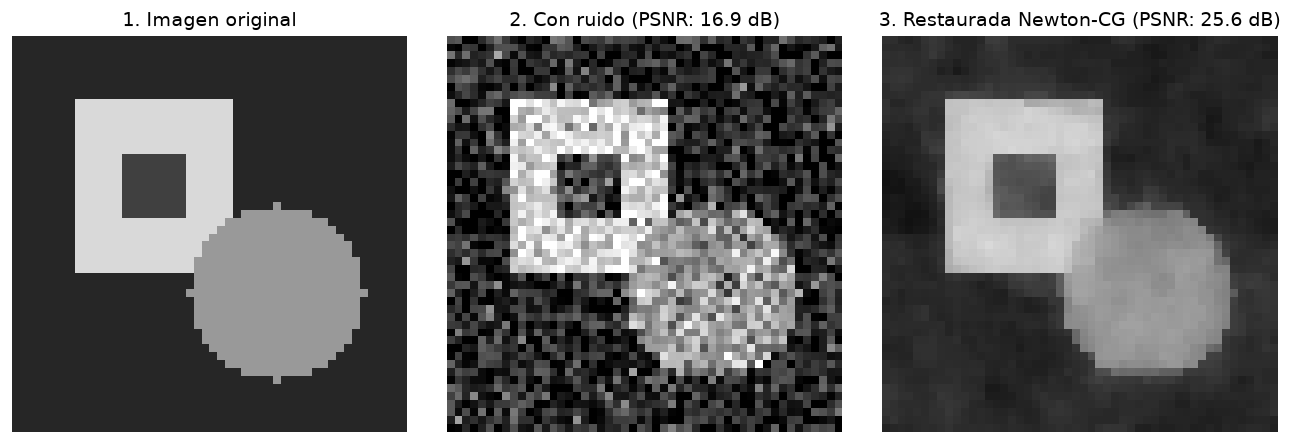

In [4]:
# 1) Creamos una imagen de prueba 50x50 con bordes nítidos (cuadrado + círculo)
H, W = 50, 50
n_vars = H * W
yy, xx = np.mgrid[0:H, 0:W]

img_limpia = np.full((H, W), 0.15)
img_limpia[8:30, 8:28] = 0.85                             # bloque rectangular brillante
img_limpia[(xx - 33)**2 + (yy - 32)**2 <= 11**2] = 0.60   # círculo gris medio
img_limpia[15:23, 14:22] = 0.25                           # ventana interna oscura

# Agregamos ruido gaussiano
img_ruido = img_limpia + rng.normal(0.0, 0.16, size=(H, W))

lam_tv = 0.18   # fuerza de suavizado
eps    = 0.03   # suavizado de la norma TV para que sea diferenciable

def psnr(ref, est):
    mse = np.mean((ref - est) ** 2)
    return 10.0 * np.log10(1.0 / mse)

# 2) Objetivo, gradiente y producto Hessiana-vector (sin construir matriz n x n)
def loss_denoise(u):
    U = u.reshape(H, W)
    dv = U[1:, :] - U[:-1, :]
    dh = U[:, 1:] - U[:, :-1]
    fidelidad = 0.5 * np.sum((U - img_ruido) ** 2)
    tv = lam_tv * (np.sum(np.sqrt(dv**2 + eps**2) - eps) + np.sum(np.sqrt(dh**2 + eps**2) - eps))
    return fidelidad + tv

def grad_denoise(u):
    U = u.reshape(H, W)
    dv = U[1:, :] - U[:-1, :]
    dh = U[:, 1:] - U[:, :-1]
    gv = lam_tv * dv / np.sqrt(dv**2 + eps**2)
    gh = lam_tv * dh / np.sqrt(dh**2 + eps**2)
    G = U - img_ruido
    G[1:, :] += gv;  G[:-1, :] -= gv
    G[:, 1:] += gh;  G[:, :-1] -= gh
    return G.ravel()

def hessp_denoise(u, v):
    U = u.reshape(H, W)
    V = v.reshape(H, W)
    dv, dh = U[1:, :] - U[:-1, :], U[:, 1:] - U[:, :-1]
    dv_v, dh_v = V[1:, :] - V[:-1, :], V[:, 1:] - V[:, :-1]
    # Segunda derivada de sqrt(d^2 + eps^2) es eps^2 / (d^2 + eps^2)^(3/2)
    wv = lam_tv * (eps**2) / (dv**2 + eps**2) ** 1.5
    wh = lam_tv * (eps**2) / (dh**2 + eps**2) ** 1.5
    HV = V.copy()
    HV[1:, :] += wv * dv_v;  HV[:-1, :] -= wv * dv_v
    HV[:, 1:] += wh * dh_v;  HV[:, :-1] -= wh * dh_v
    return HV.ravel()

# 3) Resolvemos el problema de 2,500 variables con Newton-CG y L-BFGS-B
u0 = img_ruido.ravel()

t0 = time.perf_counter()
res_ncg = minimize(loss_denoise, u0, method="Newton-CG", jac=grad_denoise, hessp=hessp_denoise, options={"xtol": 1e-4})
t_ncg = (time.perf_counter() - t0) * 1000

t0 = time.perf_counter()
res_lbfgs = minimize(loss_denoise, u0, method="L-BFGS-B", jac=grad_denoise, options={"ftol": 1e-9})
t_lbfgs = (time.perf_counter() - t0) * 1000

img_ncg   = np.clip(res_ncg.x.reshape(H, W), 0, 1)
img_lbfgs = np.clip(res_lbfgs.x.reshape(H, W), 0, 1)

print(f"Variables optimizadas : n = {n_vars:,} (Hessiana densa requeriría {n_vars**2:,} entradas)")
print(f"PSNR con ruido        : {psnr(img_limpia, np.clip(img_ruido, 0, 1)):.2f} dB")
print(f"Newton-CG (Hess-Free) : {res_ncg.nit:2d} iters | {t_ncg:6.1f} ms | PSNR: {psnr(img_limpia, img_ncg):.2f} dB")
print(f"L-BFGS-B  (m=10)      : {res_lbfgs.nit:2d} iters | {t_lbfgs:6.1f} ms | PSNR: {psnr(img_limpia, img_lbfgs):.2f} dB")

# 4) Visualización comparativa
fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.8))
paneles = [
    (img_limpia, "1. Imagen original"),
    (np.clip(img_ruido, 0, 1), f"2. Con ruido (PSNR: {psnr(img_limpia, np.clip(img_ruido, 0, 1)):.1f} dB)"),
    (img_ncg, f"3. Restaurada Newton-CG (PSNR: {psnr(img_limpia, img_ncg):.1f} dB)"),
]
for ax, (img, titulo) in zip(axes, paneles):
    ax.imshow(img, cmap="gray", vmin=0, vmax=1)
    ax.set_title(titulo)
    ax.axis("off")

plt.tight_layout()
plt.show()

---
## Resumen Práctico: ¿Cuál elegir en un proyecto real?

| Escenario | Método recomendado | Razón práctica |
| :--- | :--- | :--- |
| Pocas o medianas variables ($n \lesssim 1{,}000$) y solo tienes $\nabla f$ | **BFGS** | Convergencia superlineal sin programar segundas derivadas (Ejemplos 1 y 2). |
| Muchas variables ($n \gg 1{,}000$) y solo tienes $\nabla f$ | **L-BFGS / L-BFGS-B** | Usa memoria $O(mn)$ en lugar de $O(n^2)$; estándar en *Machine Learning* e imágenes (Ejemplo 3). |
| Muchas variables ($n \gg 1{,}000$) y puedes calcular $\nabla^2 f \cdot v$ barato | **Newton-CG (*Hessian-Free*)** | Memoria $O(n)$, evita construir la Hessiana y converge en muy pocas iteraciones externas (Ejemplos 1 y 3). |